In [2]:
from dotenv import load_dotenv
from langgraph.graph import add_messages, START, StateGraph, END
from typing import TypedDict, Annotated,List
from langchain_openai import ChatOpenAI
load_dotenv()
model = ChatOpenAI()

In [3]:
class State(TypedDict):
    messages: Annotated[List, add_messages]

In [10]:
from langchain_tavily import TavilySearch

tool = TavilySearch(
    max_results=2,
    topic="general",
    search_depth="basic" # or "advanced"
)
rest = tool.invoke("what is capital of france?")
print(rest)


ValidationError: 1 validation error for TavilySearchAPIWrapper
  Value error, Did not find tavily_api_key, please add an environment variable `TAVILY_API_KEY` which contains it, or pass `tavily_api_key` as a named parameter. [type=value_error, input_value={}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.12/v/value_error

In [ ]:
tools

In [5]:
def bot(State):
    print(f"User Query: {State['messages']}")
    return {'messages': [model.invoke(State['messages'])]}

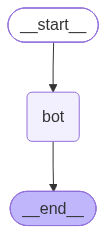

In [7]:
graph = StateGraph(State)
graph.add_node('bot', bot)
graph.set_entry_point('bot')
graph.set_finish_point('bot')
gh = graph.compile()
gh

In [8]:
gh.invoke({'messages':['Hi, Can you tell me what events happend in 1944']})

User Query: [HumanMessage(content='Hi, Can you tell me what events happend in 1944', additional_kwargs={}, response_metadata={}, id='2db3be88-9901-4fd1-8a93-b26beeb00686')]


{'messages': [HumanMessage(content='Hi, Can you tell me what events happend in 1944', additional_kwargs={}, response_metadata={}, id='2db3be88-9901-4fd1-8a93-b26beeb00686'),
  AIMessage(content='Here are some significant events that occurred in 1944:\n\n1. The Allied invasion of Normandy, known as D-Day, took place on June 6, 1944. This marked the beginning of the liberation of Western Europe from Nazi control during World War II.\n\n2. The Battle of the Bulge, a major German offensive against the Allied forces in the Ardennes region of Belgium and Luxembourg, took place from December 16, 1944, to January 25, 1945.\n\n3. The Warsaw Uprising, a major act of resistance against German occupation in Poland, began on August 1, 1944, and lasted until October 2, 1944.\n\n4. The Soviet Union launched Operation Bagration, a major offensive against German forces on the Eastern Front, on June 22, 1944. This operation led to the liberation of Belarus and eastern Poland.\n\n5. The Bretton Woods Con